# Gene expression prediction (Path2Space) on the OVCA ROI cell population

Runs [LazySlide's Path2Space gene-expression-prediction tutorial](https://lazyslide.readthedocs.io/en/latest/tutorials/gene_expression_prediction.html) on CTransPath features, for the **same 17,278-cell / 36-ROI population** used by `scripts/extract_cell_embeddings_roi.py` (which produced the virchow2 and uni2 embeddings).

**Why this can't just reuse ctranspath embeddings from that script (or add ctranspath to it directly):** Path2Space's head was fit on CTransPath features computed with a *specific* preprocessing pipeline -- Macenko stain normalisation + brightness standardisation + `amp=False` -- not CTransPath's default preprocessing (`amp=True`, no stain normalisation, which is what `extract_cell_embeddings_roi.py` uses for virchow2/uni2). Same 768-d output shape, different input distribution, so predictions from the default pipeline would be silently wrong rather than erroring. This exact fix was already validated on this exact slide in `goofys_wsi_ood/scripts/OVCA_path2space_pilot.py` (a 5% pilot); this notebook reuses that preprocessing against the **full** ROI cell population instead of a random subsample, so predictions land on the same cells as the cell_type/domain classifiers already trained in `05_roi_embedding_classifiers.ipynb`.

**Bonus over the original pilot:** this Xenium panel actually measured 5,101 genes per cell directly, and 3,604 of them are also in Path2Space's own reference gene set -- so predictions can be validated against real ground truth (section 7 below), not just trusted blindly the way a pure Visium/HEST inference-only setting would have to.

Run with the **`lazyslide-env`** kernel (needs `torch`, `torchstain`, `lazyslide`, `lazyslide_models`; a GPU is required for CTransPath + Path2Space inference).

In [12]:
import json
from pathlib import Path

import anndata as ad
ad.settings.allow_write_nullable_strings = True  # cell_id is Arrow-backed (from cells.parquet)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torchstain
from scipy.stats import spearmanr
from torchvision.transforms.v2 import Compose, Normalize, Resize, ToDtype, ToImage

import spatialdata as sd
from wsidata import TileSpec, open_wsi
from wsidata.io import add_tiles

import lazyslide as zs
from lazyslide_models.feature_prediction.path2space import Path2Space

# absolute paths: kernel cwd depends on how Jupyter was launched/connected, so a relative
# "../data" path is not reliable (e.g. VSCode "Existing Jupyter Server") -- same convention as
# 05_roi_embedding_classifiers.ipynb.
REPO_ROOT = Path("/g/stegle/spiljak/projects/main_wsi_ood")
SDATA_PATH = REPO_ROOT / "notebooks" / "datasets" / "OVCA.zarr"
ROI_H5AD_PATH = REPO_ROOT / "data" / "ovca_roi_embeddings" / "ovca_roi_cell_embeddings.h5ad"
OUT_DIR = REPO_ROOT / "data" / "ovca_path2space"
OUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_KEY = "he"
HE_MPP = 0.2738174784591427
TILE_PX = 224
TILE_MPP = 0.5
# Path2Space is a large model returning one column per gene; predict in chunks rather than
# materialising [n_cells, n_genes] activations on the GPU in one shot.
PREDICT_CHUNK = 512

## 1. Load the slide (persist H&E in memory)

In [2]:
print(f"Loading spatialdata zarr: {SDATA_PATH}")
sdata = sd.read_zarr(SDATA_PATH)
table = sdata.tables["table"]

# Same fix as extract_cell_embeddings_roi.py: wsidata's SpatialDataImage2DReader.get_region()
# calls .compute() on EVERY tile read with no caching between calls, so nearby tiles repeatedly
# re-fetch/decompress the same zarr chunk from disk (measured: ~640GB read for one ~17k-tile run
# vs. ~9GB of actual tile pixels). Persisting the ~4GB image into RAM once turns every subsequent
# per-tile read into a free in-memory slice (~60-70x faster in isolated benchmarks).
print("Persisting he image into memory (one-time ~4GB) to eliminate per-tile disk re-reads...")
sdata.images[IMAGE_KEY] = sdata.images[IMAGE_KEY].persist()
print("Persisted.")

wsi = open_wsi(sdata, image_key=IMAGE_KEY)
wsi.set_mpp(HE_MPP)
print(f"Loaded OVCA: {table.n_obs} cells, H&E mpp={HE_MPP}")

Loading spatialdata zarr: /g/stegle/spiljak/projects/main_wsi_ood/notebooks/datasets/OVCA.zarr
Persisting he image into memory (one-time ~4GB) to eliminate per-tile disk re-reads...
Persisted.
Loaded OVCA: 407124 cells, H&E mpp=0.2738174784591427


## 2. Reuse the exact ROI cell population

Loading `obs` straight from the already-computed embeddings h5ad (rather than re-deriving ROI placement) guarantees this notebook's predictions land on **exactly** the same 17,278 cells / 36 ROIs as the virchow2 and uni2 runs -- same `cell_id`, `x_he`/`y_he`, `roi_id`, `roi_domain`. ROI placement is otherwise deterministic (fixed RNG seed) so re-deriving it would give the same result anyway, but reading it from the h5ad is simpler and removes any chance of drift.

In [3]:
roi_adata = ad.read_h5ad(ROI_H5AD_PATH)
cells = roi_adata.obs.reset_index(drop=True).copy()
print(f"Loaded {len(cells)} cells from {ROI_H5AD_PATH.name} (same population as virchow2/uni2)")
print(f"n ROIs: {cells['roi_id'].nunique()}")
print()
print("cells per roi_domain:")
print(cells["roi_domain"].value_counts())

Loaded 17278 cells from ovca_roi_cell_embeddings.h5ad (same population as virchow2/uni2)
n ROIs: 36

cells per roi_domain:
roi_domain
Tumor             8194
Smooth muscle     4348
Fallopian tube    2592
Necrosis          1490
Ovary              654
Name: count, dtype: int64


## 3. Register the same cell-centred tiles

Fresh `add_tiles` call in this notebook's own `wsi`/`tile_key` -- `tile_id` values are assigned in call order, so they are NOT the same integers as in the original script's run; `cells["tile_id"]` below is overwritten with this notebook's own assignment and used consistently from here on (same pattern `extract_cell_embeddings_roi.py` and `OVCA_path2space_pilot.py` both use).

In [4]:
tile_spec = TileSpec.from_wsidata(wsi, tile_px=TILE_PX, mpp=TILE_MPP)
half_w, half_h = tile_spec.base_width / 2, tile_spec.base_height / 2
xys = np.c_[cells["x_he"].to_numpy() - half_w, cells["y_he"].to_numpy() - half_h]

tile_key = "path2space_tiles"
add_tiles(wsi, key=tile_key, xys=xys, tile_spec=tile_spec, tissue_ids=np.zeros(len(xys), dtype=int))
wsi.shapes[tile_key]["cell_id"] = cells["cell_id"].to_numpy()
cells["tile_id"] = wsi.shapes[tile_key]["tile_id"].to_numpy()
print(f"Registered {len(xys)} cell-centred tiles (FOV {TILE_PX * TILE_MPP:.0f}um)")

Registered 17278 cell-centred tiles (FOV 112um)


## 4. Macenko-normalised CTransPath transform (required for Path2Space)

Reproduces `OVCA_path2space_pilot.py`'s `path2space_macenko` transform exactly: brightness-standardise to the 95th percentile, then Macenko stain-normalise, then the standard ImageNet CTransPath transform. Path2Space's head was fitted on features from this precise pipeline -- the default ctranspath preprocessing (as used for virchow2/uni2 in `extract_cell_embeddings_roi.py`) is NOT valid input here, despite the 768-d shape matching.

In [5]:
macenko_normalizer = torchstain.normalizers.MacenkoNormalizer(backend="torch")
ctranspath_transform = Compose(
    [
        ToImage(),
        ToDtype(dtype=torch.float32, scale=True),
        Resize(size=(224, 224), antialias=False),
        Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ]
)


def path2space_macenko(tile, return_rgb=False):
    tile = np.asarray(tile, dtype=np.uint8)
    brightness = np.percentile(tile, 95)
    brightness = max(brightness, 1.0)
    standardized = np.clip(tile.astype(np.float32) * 255.0 / brightness, 0, 255).astype(np.uint8)
    tensor = torch.from_numpy(standardized.copy()).permute(2, 0, 1)
    try:
        normalized, _, _ = macenko_normalizer.normalize(
            I=tensor, Io=255, alpha=1, beta=0.15, stains=False
        )
        normalized = normalized.clamp(0, 255).to(torch.uint8).cpu().numpy()
    except (IndexError, RuntimeError):
        # Macenko fails on near-empty / single-stain tiles; fall back to the brightness-
        # standardised tile rather than dropping the cell.
        normalized = standardized
    if return_rgb:
        return normalized
    return ctranspath_transform(normalized)

## 5. Extract CTransPath features (Macenko-normalised, `amp=False`)

In [6]:
print("Extracting ctranspath features (Macenko-normalised, amp=False) ...")
zs.tl.feature_extraction(
    wsi,
    "ctranspath",
    tile_key=tile_key,
    batch_size=64,
    amp=False,
    transform=path2space_macenko,
)
feat_adata = wsi.fetch.features_anndata("ctranspath", tile_key=tile_key, tile_graph=False)
order = np.argsort(feat_adata.obs["tile_id"].to_numpy())
assert np.array_equal(
    feat_adata.obs["tile_id"].to_numpy()[order], cells["tile_id"].to_numpy()
), "tile order mismatch"
ctranspath_features = np.asarray(feat_adata.X)[order].astype(np.float32)
print(f"CTransPath features: {ctranspath_features.shape}")
assert ctranspath_features.shape[1] == 768, f"Path2Space needs 768-d features, got {ctranspath_features.shape[1]}"


Extracting ctranspath features (Macenko-normalised, amp=False) ...


/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

CTransPath features: (17278, 768)


## 6. Predict gene expression with Path2Space

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading Path2Space (device={device}) ...")
p2s = Path2Space()
p2s.model.to(device)
genes = list(p2s.genes)
print(f"Path2Space loaded: {len(genes)} genes")

chunks = []
for start in range(0, len(ctranspath_features), PREDICT_CHUNK):
    block = ctranspath_features[start : start + PREDICT_CHUNK]
    pred = p2s.predict(block)
    chunks.append(np.column_stack([pred[g] for g in genes]).astype(np.float32))
    if (start // PREDICT_CHUNK) % 10 == 0:
        print(f"  predicted {min(start + PREDICT_CHUNK, len(ctranspath_features))}/{len(ctranspath_features)} cells")
predicted_expr = np.vstack(chunks)
print(f"Predicted expression: {predicted_expr.shape} (cells x genes)")

Loading Path2Space (device=cuda) ...
Path2Space loaded: 14068 genes
  predicted 512/17278 cells
  predicted 5632/17278 cells
  predicted 10752/17278 cells
  predicted 15872/17278 cells
Predicted expression: (17278, 14068) (cells x genes)


## 7. Validate against measured Xenium expression

Unlike the tutorial's Visium/HEST setting, this Xenium panel actually measured 5,101 genes per cell directly -- 3,604 of them are also in Path2Space's reference gene set. This lets us sanity-check predictions against real ground truth, which the original 5% pilot couldn't do. Comparison uses **Spearman correlation** (rank-based) since Path2Space's output scale and the raw Xenium counts' scale aren't necessarily comparable directly.

In [8]:
xenium_genes = table.var.index.astype(str).to_numpy()
overlap_genes = sorted(set(xenium_genes) & set(genes))
print(f"{len(overlap_genes)} genes overlap between the Xenium panel and Path2Space's reference set")

# match cells: table.obs['cell_id'] -> row index, aligned to our `cells` order
cell_id_to_row = pd.Series(np.arange(table.n_obs), index=table.obs["cell_id"].astype(str).to_numpy())
table_rows = cell_id_to_row.loc[cells["cell_id"].to_numpy()].to_numpy()

xenium_gene_to_col = pd.Series(np.arange(len(xenium_genes)), index=xenium_genes)
measured_cols = xenium_gene_to_col.loc[overlap_genes].to_numpy()
measured_counts = table.X[table_rows][:, measured_cols]
if sp.issparse(measured_counts):
    measured_counts = measured_counts.toarray()
measured_counts = np.asarray(measured_counts, dtype=np.float32)

path2space_gene_to_col = {g: i for i, g in enumerate(genes)}
pred_cols = [path2space_gene_to_col[g] for g in overlap_genes]
predicted_overlap = predicted_expr[:, pred_cols]

correlations = np.full(len(overlap_genes), np.nan)
for i in range(len(overlap_genes)):
    if measured_counts[:, i].std() > 0 and predicted_overlap[:, i].std() > 0:
        correlations[i], _ = spearmanr(measured_counts[:, i], predicted_overlap[:, i])
corr_df = (
    pd.DataFrame({"gene": overlap_genes, "spearman_r": correlations})
    .dropna()
    .sort_values("spearman_r", ascending=False)
)
print(f"Computed correlation for {len(corr_df)}/{len(overlap_genes)} genes (rest had zero variance in this cell subset)")
print(f"median r={corr_df['spearman_r'].median():.3f}  mean r={corr_df['spearman_r'].mean():.3f}")
print()
print("Top 10 best-predicted genes:")
print(corr_df.head(10).to_string(index=False))
print()
print("Bottom 10 worst-predicted genes:")
print(corr_df.tail(10).to_string(index=False))

3604 genes overlap between the Xenium panel and Path2Space's reference set
Computed correlation for 3604/3604 genes (rest had zero variance in this cell subset)
median r=0.076  mean r=0.093

Top 10 best-predicted genes:
   gene  spearman_r
  EEF1G    0.551010
   CD47    0.509488
LAPTM4B    0.492112
 HNRNPD    0.478075
    PKM    0.477060
  PRKCI    0.469892
  NORAD    0.461098
    H19    0.460630
 EIF4A1    0.449822
  YWHAZ    0.441837

Bottom 10 worst-predicted genes:
    gene  spearman_r
    SYNM   -0.072477
   ERP27   -0.073705
  PFKFB3   -0.079047
   TACC2   -0.083234
    ANO1   -0.089221
  SEMA3A   -0.094268
    ATF3   -0.097850
C11orf96   -0.121642
    MAOB   -0.128872
   NR4A1   -0.153441


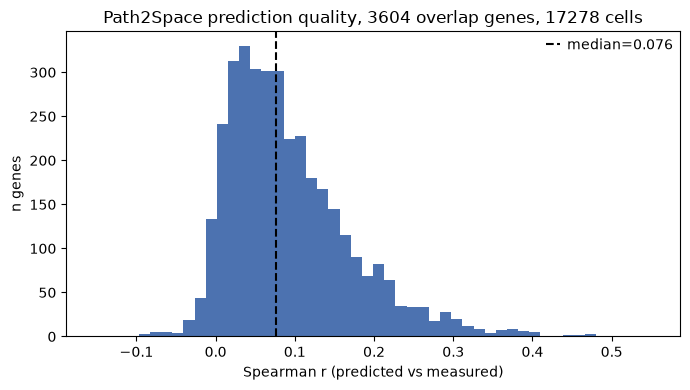

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(corr_df["spearman_r"], bins=50, color="#4C72B0")
ax.axvline(
    corr_df["spearman_r"].median(), color="black", linestyle="--",
    label=f"median={corr_df['spearman_r'].median():.3f}",
)
ax.set_xlabel("Spearman r (predicted vs measured)")
ax.set_ylabel("n genes")
ax.set_title(f"Path2Space prediction quality, {len(corr_df)} overlap genes, {len(cells)} cells")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Save outputs

In [13]:
pred_adata = ad.AnnData(
    X=predicted_expr,
    obs=cells.set_index("cell_id", drop=False),
    var=pd.DataFrame(index=pd.Index(genes, name="gene")),
)
pred_adata.obsm["ctranspath_macenko"] = ctranspath_features
pred_adata.uns["overlap_gene_correlations"] = corr_df.set_index("gene")["spearman_r"].to_dict()
h5ad_out = OUT_DIR / "ovca_path2space_predictions.h5ad"
pred_adata.write_h5ad(h5ad_out)
print(f"Saved {h5ad_out}")

summary = {
    "n_cells": int(len(cells)),
    "n_genes_predicted": len(genes),
    "n_overlap_genes": len(overlap_genes),
    "n_overlap_genes_with_variance": len(corr_df),
    "median_spearman_r": float(corr_df["spearman_r"].median()),
    "mean_spearman_r": float(corr_df["spearman_r"].mean()),
    "tile_px": TILE_PX,
    "tile_mpp": TILE_MPP,
    "macenko": True,
    "amp": False,
    "roi_source_h5ad": str(ROI_H5AD_PATH),
}
with open(OUT_DIR / "ovca_path2space_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

Saved /g/stegle/spiljak/projects/main_wsi_ood/data/ovca_path2space/ovca_path2space_predictions.h5ad
{
  "n_cells": 17278,
  "n_genes_predicted": 14068,
  "n_overlap_genes": 3604,
  "n_overlap_genes_with_variance": 3604,
  "median_spearman_r": 0.07629952607295563,
  "mean_spearman_r": 0.09303835166041029,
  "tile_px": 224,
  "tile_mpp": 0.5,
  "macenko": true,
  "amp": false,
  "roi_source_h5ad": "/g/stegle/spiljak/projects/main_wsi_ood/data/ovca_roi_embeddings/ovca_roi_cell_embeddings.h5ad"
}


## 9. QC: spatial map for the best-correlating gene

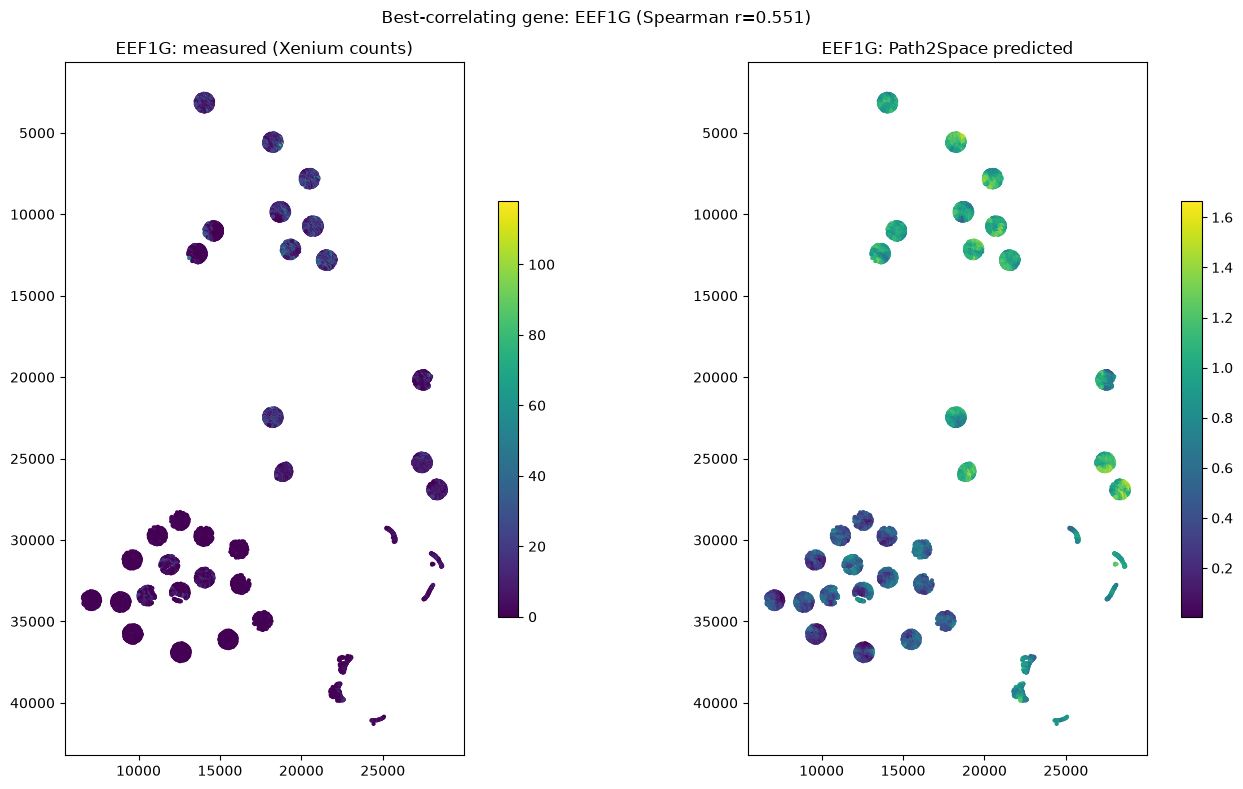

In [10]:
best_gene = corr_df.iloc[0]["gene"]
best_idx_overlap = overlap_genes.index(best_gene)
measured_vals = measured_counts[:, best_idx_overlap]
predicted_vals = predicted_overlap[:, best_idx_overlap]

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, vals, title in zip(
    axes,
    [measured_vals, predicted_vals],
    [f"{best_gene}: measured (Xenium counts)", f"{best_gene}: Path2Space predicted"],
):
    sca = ax.scatter(cells["x_he"], cells["y_he"], c=vals, s=4, cmap="viridis")
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set_title(title)
    fig.colorbar(sca, ax=ax, shrink=0.6)
fig.suptitle(f"Best-correlating gene: {best_gene} (Spearman r={corr_df.iloc[0]['spearman_r']:.3f})")
fig.tight_layout()
plt.show()